# ATML PA3 — Task 2: Vision-Language Model (SigLIP → MLP → Qwen3-0.6B) and Visual Grounding

**How to use**
1. Runtime → GPU (T4 is fine; A100/L4 is faster).
2. Run all cells. **After a disconnect, reconnect and "Run all" again** — every stage resumes from Drive:
   * data selection (all IDs) is saved once and reused,
   * image features are cached in chunks (a half-finished caching job continues at the next chunk),
   * training saves a full resumable checkpoint every 250 updates (connector, LoRA, optimizer, scheduler, scaler, stage, sampler position, RNG),
   * development evaluations and every final-evaluation suite × image condition are saved separately.
3. Optional 49-token experiment: set `N_VIS = 49` in the config cell and run again (outputs go to a separate folder; data/features are shared).

Outputs: `MyDrive/ATML_PA3/task2/`. Raw COCO/VQA files are downloaded to the VM only; features (~3 GB FP16) and all IDs live on Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install "transformers>=4.51,<5" "accelerate>=0.30" pandas matplotlib pillow requests

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
# Configuration
import os, json, math, time, random, re, gc, shutil, zipfile, io
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

ROOT = Path("/content/drive/MyDrive/ATML_PA3/task2")
LOCAL = Path("/content/task2_local")
for d in [ROOT, LOCAL, ROOT / "data", ROOT / "features", ROOT / "thumbs", LOCAL / "raw", LOCAL / "images"]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 6304
LM_ID = "Qwen/Qwen3-0.6B"
VIS_ID = "google/siglip-base-patch16-224"
N_VIS = 196                      # 196 = main run; 49 = optional 2x2-pooled compression run
RUN_TAG = f"tok{N_VIS}"
RUN = ROOT / "runs" / RUN_TAG; RUN.mkdir(parents=True, exist_ok=True)

# data sizes
N_CAP_TRAIN_IMG, CAPS_PER_IMG, N_CAP_DEV = 6000, 3, 96
VQA_TRAIN = {"yes/no": 640, "number": 256, "other": 640}
VQA_DEV = {"yes/no": 12, "number": 8, "other": 12}
VQA_TEST = {"yes/no": 36, "number": 24, "other": 36}
GROUND_DEV = {"presence": 12, "counting": 12}        # 24 pairs / 48 questions
GROUND_TEST = {"presence": 32, "counting": 32}       # 64 pairs / 128 questions
PRES_POOL, COUNT_POOL = 6000, 6000                    # reusable training pair pools
PRES_MIN_AREA = 0.01      # "yes" image: at least one non-crowd instance covering >= 1% of the image
COUNT_MIN_AREA = 0.002    # counting: every instance of the category covers >= 0.2% (tiny objects make counts ambiguous)

# training
MICRO_BS, ACCUM = 8, 2; EFF_BS = MICRO_BS * ACCUM
STAGES = [dict(name="stage1_caption",  updates=2250, lr_conn=1e-3, lr_lora=None),
          dict(name="stage2_instruct", updates=1500, lr_conn=1e-4, lr_lora=2e-5),
          dict(name="stage3_vqa",      updates=750,  lr_conn=5e-5, lr_lora=1e-5)]
STAGE_START = np.cumsum([0] + [s["updates"] for s in STAGES])[:-1].tolist()   # [0, 2250, 3750]
STAGE_END = [a + s["updates"] for a, s in zip(STAGE_START, STAGES)]           # [2250, 3750, 4500]
TOTAL = STAGE_END[-1]
STAGE2_MIX = {"presence": 0.50, "counting": 0.25, "caption": 0.25}
STAGE3_MIX = {"vqa": 0.70, "presence": 0.10, "counting": 0.10, "caption": 0.10}
WD, CLIP = 0.01, 1.0
LORA_R, LORA_ALPHA, LORA_DROP = 16, 32, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj"]
Q_CAP, CAP_CAP, ANS_CAP = 80, 64, 16
CKPT_EVERY = 250
DEV_POINTS = sorted({0, *range(500, TOTAL + 1, 500), *STAGE_END})
MAX_NEW, GEN_BS = 16, 8
N_BOOT = 4000

CAPTION_INSTR = "Write a short caption for this image."
QA_INSTR = "Answer the question using a single word or number."

assert torch.cuda.is_available()
print(torch.cuda.get_device_name(0), "| run", RUN_TAG)

Tesla T4 | run tok196


In [4]:
# Utilities
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def jdump(obj, path):
    path = Path(path); tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w") as f: json.dump(obj, f, indent=1, default=str)
    os.replace(tmp, path)

def jload(path):
    with open(path) as f: return json.load(f)

def atomic_torch_save(obj, path):
    path = Path(path); local_tmp = LOCAL / ("_tmp_" + path.name)
    torch.save(obj, local_tmp)
    tmp = path.with_name(path.name + ".tmp"); shutil.copyfile(local_tmp, tmp); os.replace(tmp, path); os.remove(local_tmp)

def rng_state():
    return {"torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all(),
            "numpy": np.random.get_state(), "python": random.getstate()}

def set_rng_state(s):
    torch.set_rng_state(s["torch"]); torch.cuda.set_rng_state_all(s["cuda"])
    np.random.set_state(s["numpy"]); random.setstate(s["python"])

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

# ---- official VQA answer normalisation (vqaEval.py), used for training targets, voting and scoring ----
CONTRACTIONS = {"aint": "ain't", "arent": "aren't", "cant": "can't", "couldve": "could've", "couldnt": "couldn't",
    "couldn'tve": "couldn't've", "couldnt've": "couldn't've", "didnt": "didn't", "doesnt": "doesn't", "dont": "don't",
    "hadnt": "hadn't", "hadnt've": "hadn't've", "hadn'tve": "hadn't've", "hasnt": "hasn't", "havent": "haven't",
    "hed": "he'd", "hed've": "he'd've", "he'dve": "he'd've", "hes": "he's", "howd": "how'd", "howll": "how'll",
    "hows": "how's", "id've": "i'd've", "i'dve": "i'd've", "im": "i'm", "ive": "i've", "isnt": "isn't", "itd": "it'd",
    "itd've": "it'd've", "it'dve": "it'd've", "itll": "it'll", "let's": "let's", "maam": "ma'am", "mightnt": "mightn't",
    "mightnt've": "mightn't've", "mightn'tve": "mightn't've", "mightve": "might've", "mustnt": "mustn't",
    "mustve": "must've", "neednt": "needn't", "notve": "not've", "oclock": "o'clock", "oughtnt": "oughtn't",
    "ow's'at": "'ow's'at", "'ows'at": "'ow's'at", "'ow'sat": "'ow's'at", "shant": "shan't", "shed've": "she'd've",
    "she'dve": "she'd've", "she's": "she's", "shouldve": "should've", "shouldnt": "shouldn't",
    "shouldnt've": "shouldn't've", "shouldn'tve": "shouldn't've", "somebody'd": "somebodyd",
    "somebodyd've": "somebody'd've", "somebody'dve": "somebody'd've", "somebodyll": "somebody'll",
    "somebodys": "somebody's", "someoned": "someone'd", "someoned've": "someone'd've", "someone'dve": "someone'd've",
    "someonell": "someone'll", "someones": "someone's", "somethingd": "something'd", "somethingd've": "something'd've",
    "something'dve": "something'd've", "somethingll": "something'll", "thats": "that's", "thered": "there'd",
    "thered've": "there'd've", "there'dve": "there'd've", "therere": "there're", "theres": "there's", "theyd": "they'd",
    "theyd've": "they'd've", "they'dve": "they'd've", "theyll": "they'll", "theyre": "they're", "theyve": "they've",
    "twas": "'twas", "wasnt": "wasn't", "wed've": "we'd've", "we'dve": "we'd've", "weve": "we've", "werent": "weren't",
    "whatll": "what'll", "whatre": "what're", "whats": "what's", "whatve": "what've", "whens": "when's",
    "whered": "where'd", "wheres": "where's", "whereve": "where've", "whod": "who'd", "whod've": "who'd've",
    "who'dve": "who'd've", "wholl": "who'll", "whos": "who's", "whove": "who've", "whyll": "why'll", "whyre": "why're",
    "whys": "why's", "wont": "won't", "wouldve": "would've", "wouldnt": "wouldn't", "wouldnt've": "wouldn't've",
    "wouldn'tve": "wouldn't've", "yall": "y'all", "yall'll": "y'all'll", "y'allll": "y'all'll", "yall'd've": "y'all'd've",
    "y'alld've": "y'all'd've", "y'all'dve": "y'all'd've", "youd": "you'd", "youd've": "you'd've", "you'dve": "you'd've",
    "youll": "you'll", "youre": "you're", "youve": "you've"}
MANUAL_MAP = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
              "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
ARTICLES = {"a", "an", "the"}
PERIOD_STRIP = re.compile(r"(?!<=\d)(\.)(?!\d)")
COMMA_STRIP = re.compile(r"(\d)(,)(\d)")
PUNCT = [";", r"/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]

import functools
def vqa_normalize(ans): return _vqa_norm(str(ans))

@functools.lru_cache(maxsize=None)
def _vqa_norm(ans):
    t = ans.replace("\n", " ").replace("\t", " ").strip()
    out = t
    for p in PUNCT:
        if (p + " " in t or " " + p in t) or (re.search(COMMA_STRIP, t) is not None): out = out.replace(p, "")
        else: out = out.replace(p, " ")
    out = PERIOD_STRIP.sub("", out)
    words = [MANUAL_MAP.get(w, w) for w in out.lower().split()]
    words = [CONTRACTIONS.get(w, w) for w in words if w not in ARTICLES]
    return " ".join(words)

def vqa_soft_acc(pred_norm, refs_norm):
    """Local VQA consensus accuracy: mean over the 10 leave-one-out subsets of min(1, matches/3)."""
    m = [r == pred_norm for r in refs_norm]
    return float(np.mean([min(1.0, (sum(m) - m[i]) / 3.0) for i in range(len(refs_norm))]))

assert vqa_normalize("Two dogs.") == "2 dogs" and vqa_normalize("the Yes") == "yes"
assert abs(vqa_soft_acc("2", ["2"] * 3 + ["3"] * 7) - 0.9) < 1e-9

In [5]:
# Step 0 — download annotations (VM-local) and select every split deterministically (saved to Drive once)
import requests
SEL_PATH = ROOT / "data" / "selection.json"

def fetch(url, dest):
    dest = Path(dest)
    if dest.exists(): return dest
    print("downloading", url)
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        tmp = dest.with_suffix(".part")
        with open(tmp, "wb") as f:
            for ch in r.iter_content(1 << 22): f.write(ch)
    os.replace(tmp, dest); return dest

def unzip_find(zpath, pattern):
    with zipfile.ZipFile(zpath) as z:
        names = [n for n in z.namelist() if re.search(pattern, n)]
        assert names, (zpath, pattern)
        out = LOCAL / "raw" / Path(names[0]).name
        if not out.exists():
            with z.open(names[0]) as src, open(out, "wb") as dst: shutil.copyfileobj(src, dst)
    return out

VQA_BASE = "https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa/"
def load_raw():
    ann_zip = fetch("http://images.cocodataset.org/annotations/annotations_trainval2014.zip", LOCAL / "raw" / "ann2014.zip")
    R = {}
    for sp in ["train", "val"]:
        R[f"cap_{sp}"] = json.load(open(unzip_find(ann_zip, rf"captions_{sp}2014\.json")))
        R[f"inst_{sp}"] = json.load(open(unzip_find(ann_zip, rf"instances_{sp}2014\.json")))
        Sp = sp.capitalize()
        q = fetch(VQA_BASE + f"v2_Questions_{Sp}_mscoco.zip", LOCAL / "raw" / f"vqa_q_{sp}.zip")
        a = fetch(VQA_BASE + f"v2_Annotations_{Sp}_mscoco.zip", LOCAL / "raw" / f"vqa_a_{sp}.zip")
        p = fetch(VQA_BASE + f"v2_Complementary_Pairs_{Sp}_mscoco.zip", LOCAL / "raw" / f"vqa_p_{sp}.zip")
        R[f"vq_{sp}"] = json.load(open(unzip_find(q, r"questions\.json$")))["questions"]
        R[f"va_{sp}"] = json.load(open(unzip_find(a, r"annotations\.json$")))["annotations"]
        R[f"vp_{sp}"] = json.load(open(unzip_find(p, r"pairs\.json$")))
    return R

PLURAL = {"person": "people", "mouse": "mice", "knife": "knives", "sheep": "sheep", "skis": "skis",
          "scissors": "scissors", "broccoli": "broccoli"}
def plural(n):
    if n in PLURAL: return PLURAL[n]
    if re.search(r"(s|x|ch|sh)$", n): return n + "es"
    if re.search(r"[^aeiou]y$", n): return n[:-1] + "ies"
    return n + "s"
def with_article(n):
    if n in ("skis", "scissors", "broccoli"): return n
    return ("an " if n[0] in "aeiou" else "a ") + n
def presence_q(name): return f"Does this image contain {with_article(name)}?"
def counting_q(name): return f"How many {plural(name)} can you see?"

def select_all():
    R = load_raw()
    rng = np.random.default_rng(SEED)
    sel = {"config": {"PRES_MIN_AREA": PRES_MIN_AREA, "COUNT_MIN_AREA": COUNT_MIN_AREA,
                      "presence_template": "Does this image contain [a/an object]?",
                      "counting_template": "How many [objects] can you see?",
                      "vqa_rule": ">=8/10 normalised agreement on both images, different consensus answers, same answer type"}}
    used_eval = set()                                    # all dev/test images (val2014), kept disjoint

    # ---------- natural VQAv2 complementary pairs ----------
    def vqa_candidates(sp):
        qs = {q["question_id"]: q for q in R[f"vq_{sp}"]}
        an = {a["question_id"]: a for a in R[f"va_{sp}"]}
        def info(qid):
            a = an[qid]; raw = [x["answer"] for x in a["answers"]]
            norm = [vqa_normalize(x) for x in raw]
            cons, cnt = Counter(norm).most_common(1)[0]
            canon = next(r for r, n in zip(raw, norm) if n == cons)       # an original string from the consensus group
            return {"qid": qid, "image_id": a["image_id"], "question": qs[qid]["question"], "refs": raw,
                    "consensus_norm": cons, "agree": cnt, "target": canon, "answer_type": a["answer_type"]}
        out = []
        for q1, q2 in R[f"vp_{sp}"]:
            if q1 not in an or q2 not in an: continue
            a, b = info(q1), info(q2)
            if a["agree"] >= 8 and b["agree"] >= 8 and a["consensus_norm"] != b["consensus_norm"] \
               and a["answer_type"] == b["answer_type"] and a["image_id"] != b["image_id"]:
                out.append((a, b))
        out.sort(key=lambda p: (p[0]["qid"], p[1]["qid"]))
        return out

    def pick_vqa(cands, quota, split, disjoint):
        by_t = defaultdict(list)
        for p in cands: by_t[p[0]["answer_type"]].append(p)
        chosen = []
        for t, n in quota.items():
            pool = by_t[t]; order = rng.permutation(len(pool)); k = 0
            for i in order:
                a, b = pool[i]
                ka, kb = f"{split}/{a['image_id']}", f"{split}/{b['image_id']}"
                if disjoint and (ka in used_eval or kb in used_eval): continue
                if disjoint: used_eval.update([ka, kb])
                chosen.append({"pair_id": f"vqa_{a['qid']}_{b['qid']}", "type": t,
                               "items": [{**a, "img": ka, "partner_img": kb}, {**b, "img": kb, "partner_img": ka}]})
                k += 1
                if k == n: break
            assert k == n, f"not enough {t} pairs"
        return chosen

    vtr, vva = vqa_candidates("train"), vqa_candidates("val")
    print("VQA candidate pairs: train", len(vtr), "val", len(vva))
    sel["vqa_train"] = pick_vqa(vtr, VQA_TRAIN, "train2014", disjoint=False)
    sel["vqa_test"] = pick_vqa(vva, VQA_TEST, "val2014", disjoint=True)
    sel["vqa_dev"] = pick_vqa(vva, VQA_DEV, "val2014", disjoint=True)

    # ---------- COCO captions ----------
    caps = defaultdict(list)
    for c in R["cap_train"]["annotations"]: caps[c["image_id"]].append((c["id"], c["caption"].strip()))
    tr_ids = sorted(i for i, v in caps.items() if len(v) >= CAPS_PER_IMG)
    cap_imgs = [tr_ids[i] for i in rng.choice(len(tr_ids), N_CAP_TRAIN_IMG, replace=False)]
    sel["caption_train"] = []
    for im in cap_imgs:
        cs = sorted(caps[im])
        for j in sorted(rng.choice(len(cs), CAPS_PER_IMG, replace=False)):
            sel["caption_train"].append({"img": f"train2014/{im}", "caption_id": cs[j][0], "caption": cs[j][1]})

    # ---------- annotation-derived grounding ----------
    def index_instances(inst):
        cats = {c["id"]: c["name"] for c in inst["categories"]}
        wh = {im["id"]: im["width"] * im["height"] for im in inst["images"]}
        per = defaultdict(lambda: defaultdict(list))
        for a in inst["annotations"]:
            per[a["image_id"]][a["category_id"]].append((a["area"] / wh[a["image_id"]], a["iscrowd"]))
        return cats, per, sorted(wh)

    def pres_yes(per, im, c): return any(cr == 0 and ar >= PRES_MIN_AREA for ar, cr in per[im].get(c, []))
    def pres_no(per, im, c): return c not in per[im]
    def count_of(per, im, c):
        L = per[im].get(c, [])
        if not L or any(cr for _, cr in L) or any(ar < COUNT_MIN_AREA for ar, _ in L) or len(L) > 4: return None
        return len(L)

    def grounding_pairs(cats, per, img_ids, split, quota_p, quota_c, disjoint):
        img_ids = sorted(img_ids)
        yes = {c: [i for i in img_ids if pres_yes(per, i, c)] for c in cats}
        no = {c: [i for i in img_ids if pres_no(per, i, c)] for c in cats}
        cnt = {c: defaultdict(list) for c in cats}
        for i in img_ids:
            for c in per[i]:
                k = count_of(per, i, c)
                if k: cnt[c][k].append(i)
        pcats = sorted(c for c in cats if yes[c] and no[c])
        ccats = sorted(c for c in cats if sum(1 for k in cnt[c] if cnt[c][k]) >= 2)
        out, seen, local_used = [], set(), set()
        def ok(*keys):
            if not disjoint: return True
            return not any(k in used_eval or k in local_used for k in keys)
        tries = 0
        while sum(p["type"] == "presence" for p in out) < quota_p:
            tries += 1; assert tries < 10**6
            c = pcats[rng.integers(len(pcats))]
            y, n = yes[c][rng.integers(len(yes[c]))], no[c][rng.integers(len(no[c]))]
            ky, kn = f"{split}/{y}", f"{split}/{n}"
            if (c, y, n) in seen or not ok(ky, kn): continue
            seen.add((c, y, n)); local_used.update([ky, kn]) if disjoint else None
            q = presence_q(cats[c])
            out.append({"pair_id": f"pres_{split[:3]}_{c}_{y}_{n}", "type": "presence", "category": cats[c], "items": [
                {"img": ky, "partner_img": kn, "question": q, "target": "yes", "refs": ["yes"]},
                {"img": kn, "partner_img": ky, "question": q, "target": "no", "refs": ["no"]}]})
        while sum(p["type"] == "counting" for p in out) < quota_c:
            tries += 1; assert tries < 10**6
            c = ccats[rng.integers(len(ccats))]
            ks = sorted(k for k in cnt[c] if cnt[c][k])
            k1, k2 = rng.choice(ks, 2, replace=False)
            i1, i2 = cnt[c][k1][rng.integers(len(cnt[c][k1]))], cnt[c][k2][rng.integers(len(cnt[c][k2]))]
            ka, kb = f"{split}/{i1}", f"{split}/{i2}"
            if (c, i1, i2) in seen or not ok(ka, kb): continue
            seen.add((c, i1, i2)); local_used.update([ka, kb]) if disjoint else None
            q = counting_q(cats[c])
            out.append({"pair_id": f"cnt_{split[:3]}_{c}_{i1}_{i2}", "type": "counting", "category": cats[c], "items": [
                {"img": ka, "partner_img": kb, "question": q, "target": str(int(k1)), "refs": [str(int(k1))]},
                {"img": kb, "partner_img": ka, "question": q, "target": str(int(k2)), "refs": [str(int(k2))]}]})
        if disjoint: used_eval.update(local_used)
        return out

    cats_tr, per_tr, _ = index_instances(R["inst_train"])
    pool_imgs = set(cap_imgs) | {int(it["img"].split("/")[1]) for p in sel["vqa_train"] for it in p["items"]}
    pool_imgs = [i for i in pool_imgs]
    sel["ground_train_pool"] = grounding_pairs(cats_tr, per_tr, pool_imgs, "train2014", PRES_POOL, COUNT_POOL, False)
    cats_va, per_va, val_ids = index_instances(R["inst_val"])
    val_free = [i for i in val_ids if f"val2014/{i}" not in used_eval]
    sel["ground_test"] = grounding_pairs(cats_va, per_va, val_free, "val2014",
                                         GROUND_TEST["presence"], GROUND_TEST["counting"], True)
    val_free = [i for i in val_ids if f"val2014/{i}" not in used_eval]
    sel["ground_dev"] = grounding_pairs(cats_va, per_va, val_free, "val2014",
                                        GROUND_DEV["presence"], GROUND_DEV["counting"], True)

    # ---------- caption dev (96 val images, one caption each) ----------
    vcaps = defaultdict(list)
    for c in R["cap_val"]["annotations"]: vcaps[c["image_id"]].append((c["id"], c["caption"].strip()))
    vfree = sorted(i for i in vcaps if f"val2014/{i}" not in used_eval)
    sel["caption_dev"] = []
    for i in rng.permutation(len(vfree))[:N_CAP_DEV]:
        im = vfree[i]; cs = sorted(vcaps[im]); j = rng.integers(len(cs))
        sel["caption_dev"].append({"img": f"val2014/{im}", "caption_id": cs[j][0], "caption": cs[j][1]})
        used_eval.add(f"val2014/{im}")
    return sel

if not SEL_PATH.exists():
    t0 = time.time(); SEL = select_all(); jdump(SEL, SEL_PATH)
    print(f"selection done in {time.time() - t0:.0f}s")
SEL = jload(SEL_PATH)

def suite_images(key):
    if key.startswith("caption"): return [e["img"] for e in SEL[key]]
    return [it["img"] for p in SEL[key] for it in p["items"]]

# split-isolation checks
eval_sets = {k: set(suite_images(k)) for k in ["caption_dev", "ground_dev", "ground_test", "vqa_dev", "vqa_test"]}
train_imgs = set(suite_images("caption_train")) | set(suite_images("vqa_train")) | set(suite_images("ground_train_pool"))
for a in eval_sets:
    assert not (eval_sets[a] & train_imgs), f"{a} overlaps training"
    for b in eval_sets:
        if a < b: assert not (eval_sets[a] & eval_sets[b]), f"{a} overlaps {b}"
    assert all(k.startswith("val2014/") for k in eval_sets[a])
assert all(k.startswith("train2014/") for k in train_imgs)
print({k: len(SEL[k]) for k in SEL if k != "config"}, "| eval image sets disjoint ✓")
print("VQA train types:", Counter(p["type"] for p in SEL["vqa_train"]),
      "| ground test:", Counter(p["type"] for p in SEL["ground_test"]))
jdump({k: [p["pair_id"] for p in SEL[k]] for k in ["vqa_train", "vqa_dev", "vqa_test", "ground_dev", "ground_test"]},
      ROOT / "data" / "pair_ids.json")

{'vqa_train': 1536, 'vqa_test': 96, 'vqa_dev': 32, 'caption_train': 18000, 'ground_train_pool': 12000, 'ground_test': 64, 'ground_dev': 24, 'caption_dev': 96} | eval image sets disjoint ✓
VQA train types: Counter({'yes/no': 640, 'other': 640, 'number': 256}) | ground test: Counter({'presence': 32, 'counting': 32})


In [6]:
# Step 1a — download images (only the ones whose feature chunk is still missing) and cache SigLIP features
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

ALL_KEYS = sorted(train_imgs | set().union(*eval_sets.values()))
KEY2ROW = {k: i for i, k in enumerate(ALL_KEYS)}
CHUNK = 1024
N_CHUNKS = math.ceil(len(ALL_KEYS) / CHUNK)
jdump(ALL_KEYS, ROOT / "features" / "keys.json")
TEST_KEYS = eval_sets["ground_test"] | eval_sets["vqa_test"]

def img_url(key):
    sp, i = key.split("/"); return f"http://images.cocodataset.org/{sp}/COCO_{sp}_{int(i):012d}.jpg"
def img_path(key): return LOCAL / "images" / (key.replace("/", "_") + ".jpg")

def download(keys):
    def one(k):
        p = img_path(k)
        if p.exists() and p.stat().st_size > 0: return
        for attempt in range(5):
            try:
                r = requests.get(img_url(k), timeout=60); r.raise_for_status()
                tmp = p.with_suffix(".part"); tmp.write_bytes(r.content); os.replace(tmp, p); return
            except Exception as e:
                time.sleep(2 * (attempt + 1))
        raise RuntimeError(f"failed {k}")
    with ThreadPoolExecutor(32) as ex: list(ex.map(one, keys))

feat_info_path = ROOT / "features" / "caching_info.json"
missing = [c for c in range(N_CHUNKS) if not (ROOT / "features" / f"chunk_{c:03d}.npy").exists()]
if missing:
    from transformers import SiglipVisionModel, SiglipImageProcessor
    proc = SiglipImageProcessor.from_pretrained(VIS_ID)
    vm = SiglipVisionModel.from_pretrained(VIS_ID, torch_dtype=torch.float32).cuda().eval()
    torch.cuda.reset_peak_memory_stats()
    info = jload(feat_info_path) if feat_info_path.exists() else {"download_s": 0.0, "encode_s": 0.0}
    for c in missing:
        keys = ALL_KEYS[c * CHUNK:(c + 1) * CHUNK]
        t0 = time.time(); download(keys); info["download_s"] += time.time() - t0
        torch.cuda.synchronize(); t0 = time.time()
        out = np.zeros((len(keys), 196, 768), dtype=np.float16)
        for s in range(0, len(keys), 64):
            ims = [Image.open(img_path(k)).convert("RGB") for k in keys[s:s + 64]]
            px = proc(images=ims, return_tensors="pt")["pixel_values"].cuda()
            with torch.no_grad():
                o = vm(pixel_values=px, output_hidden_states=True)
            if c == missing[0] and s == 0:   # final LayerNorm applied exactly once: last_hidden_state == post_ln(encoder output)
                ref = vm.vision_model.post_layernorm(o.hidden_states[-1])
                assert torch.allclose(ref, o.last_hidden_state, atol=1e-4), "post-layernorm check failed"
                assert o.last_hidden_state.shape[1:] == (196, 768)
            out[s:s + len(ims)] = o.last_hidden_state.half().cpu().numpy()      # 14x14 row-major patch order
            for k, im in zip(keys[s:s + 64], ims):                               # small thumbnails for qualitative figures
                if k in TEST_KEYS and not (ROOT / "thumbs" / (k.replace("/", "_") + ".jpg")).exists():
                    im.resize((224, 224)).save(ROOT / "thumbs" / (k.replace("/", "_") + ".jpg"), quality=85)
        torch.cuda.synchronize(); info["encode_s"] += time.time() - t0
        np.save(LOCAL / "chunk.npy", out); shutil.copyfile(LOCAL / "chunk.npy", ROOT / "features" / f"chunk_{c:03d}.npy.tmp")
        os.replace(ROOT / "features" / f"chunk_{c:03d}.npy.tmp", ROOT / "features" / f"chunk_{c:03d}.npy")
        info["peak_gpu_mem_GB"] = max(info.get("peak_gpu_mem_GB", 0), torch.cuda.max_memory_allocated() / 2**30)
        info.update(n_images=len(ALL_KEYS), feature_dtype="float16", shape=[196, 768])
        jdump(info, feat_info_path)
        print(f"chunk {c + 1}/{N_CHUNKS} cached")
        for k in keys: img_path(k).unlink(missing_ok=True)
    del vm; free_gpu()                       # vision encoder leaves the GPU before Qwen is trained
print("feature caching:", jload(feat_info_path))

# consolidate into one local memory-mapped array
FEAT_LOCAL = LOCAL / "features_all.npy"
if not FEAT_LOCAL.exists():
    arr = np.lib.format.open_memmap(LOCAL / "features_all.tmp.npy", mode="w+", dtype=np.float16, shape=(len(ALL_KEYS), 196, 768))
    for c in range(N_CHUNKS):
        x = np.load(ROOT / "features" / f"chunk_{c:03d}.npy"); arr[c * CHUNK:c * CHUNK + len(x)] = x
    arr.flush(); del arr; os.replace(LOCAL / "features_all.tmp.npy", FEAT_LOCAL)
FEATS = np.load(FEAT_LOCAL, mmap_mode="r")
print("features:", FEATS.shape, FEATS.dtype)

feature caching: {'download_s': 118.46788430213928, 'encode_s': 220.25972056388855, 'peak_gpu_mem_GB': 1.762681007385254, 'n_images': 9279, 'feature_dtype': 'float16', 'shape': [196, 768]}
features: (9279, 196, 768) float16


In [7]:
# Step 1b — language model, tokenised examples, connector, LoRA
from transformers import AutoTokenizer, AutoModelForCausalLM, DynamicCache

tok = AutoTokenizer.from_pretrained(LM_ID)
IM_END = tok.convert_tokens_to_ids("<|im_end|>")
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
EOS_IDS = {IM_END, tok.eos_token_id}
_ph = tok.convert_tokens_to_ids("<|image_pad|>")
PH_ID = _ph if isinstance(_ph, int) and _ph != tok.unk_token_id else PAD_ID     # placeholder; embeddings are replaced
IMG_MARK = "<<IMAGE>>"

def split_prompt(text):
    """Chat template (thinking disabled) with the visual tokens at the start of the user message."""
    full = tok.apply_chat_template([{"role": "user", "content": IMG_MARK + "\n" + text}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)
    before, after = full.split(IMG_MARK)
    return tok(before, add_special_tokens=False)["input_ids"], tok(after, add_special_tokens=False)["input_ids"]

PROMPTS, PKEY = [], {}
def prompt_key(kind, question=None):
    if kind == "caption": text = CAPTION_INSTR
    else:
        qi = tok(question, add_special_tokens=False)["input_ids"][:Q_CAP]           # question content cap
        text = tok.decode(qi) + "\n" + QA_INSTR
    if text not in PKEY: PKEY[text] = len(PROMPTS); PROMPTS.append(split_prompt(text))
    return PKEY[text]

EX = []        # global example table
def add_ex(kind, img, target, question=None, refs=None, pair_id=None, partner=None, qtype=None):
    cap = CAP_CAP if kind == "caption" else ANS_CAP
    EX.append({"kind": kind, "row": KEY2ROW[img], "img": img, "pk": prompt_key(kind, question),
               "tgt": tok(target, add_special_tokens=False)["input_ids"][:cap], "target": target,
               "question": question, "refs": refs, "pair_id": pair_id,
               "partner_row": KEY2ROW[partner] if partner else None, "partner_img": partner, "qtype": qtype})
    return len(EX) - 1

def add_pairs(key, kind):
    out = []
    for p in SEL[key]:
        kd = kind or p["type"]
        out.append([add_ex(kd, it["img"], it["target"], it["question"], it["refs"], p["pair_id"],
                           it["partner_img"], p["type"]) for it in p["items"]])
    return out

CAP_TRAIN = [add_ex("caption", e["img"], e["caption"]) for e in SEL["caption_train"]]
CAP_DEV = [add_ex("caption", e["img"], e["caption"]) for e in SEL["caption_dev"]]
VQA_TR, VQA_DV, VQA_TE = add_pairs("vqa_train", "vqa"), add_pairs("vqa_dev", "vqa"), add_pairs("vqa_test", "vqa")
GPOOL = add_pairs("ground_train_pool", None)
PRES_PAIRS = [pr for pr, p in zip(GPOOL, SEL["ground_train_pool"]) if p["type"] == "presence"]
CNT_PAIRS = [pr for pr, p in zip(GPOOL, SEL["ground_train_pool"]) if p["type"] == "counting"]
GR_DV, GR_TE = add_pairs("ground_dev", None), add_pairs("ground_test", None)
print(len(EX), "examples |", len(PROMPTS), "distinct prompts | presence/counting pool pairs:", len(PRES_PAIRS), len(CNT_PAIRS))
print("example prompt:", repr(tok.decode(PROMPTS[EX[VQA_TR[0][0]]["pk"]][0]) + "[VIS x N]" + tok.decode(PROMPTS[EX[VQA_TR[0][0]]["pk"]][1])))

lm = AutoModelForCausalLM.from_pretrained(LM_ID, torch_dtype=torch.float16, attn_implementation="sdpa").cuda()
for p in lm.parameters(): p.requires_grad_(False)                # original weights frozen throughout
lm.config.use_cache = False
lm.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
HID = lm.config.hidden_size
EMBED = lm.get_input_embeddings()

class Connector(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(768, 1024), nn.GELU(), nn.Linear(1024, HID)
        self.register_buffer("scale", torch.ones(()))              # fixed output scale from calibration
    def forward(self, f): return self.fc2(self.act(self.fc1(f))) * self.scale

class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout, gen):
        super().__init__()
        self.base, self.scaling = base, alpha / r
        b = 1 / math.sqrt(base.in_features)
        self.lora_A = nn.Parameter(((torch.rand(r, base.in_features, generator=gen) * 2 - 1) * b).cuda())
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r, device="cuda"))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.base(x) + F.linear(F.linear(self.drop(x), self.lora_A), self.lora_B) * self.scaling

def add_lora():
    gen = torch.Generator().manual_seed(SEED + 2)
    for layer in lm.model.layers:
        for t in LORA_TARGETS:
            m = getattr(layer.self_attn, t)
            if not isinstance(m, LoRALinear): setattr(layer.self_attn, t, LoRALinear(m, LORA_R, LORA_ALPHA, LORA_DROP, gen))

def lora_params():
    return {n: p for n, p in lm.named_parameters() if "lora_" in n}

def visual_feats(rows):
    f = torch.from_numpy(np.ascontiguousarray(FEATS[np.asarray(rows)])).cuda().float()
    if N_VIS == 49:   # optional compression: average each 2x2 block of the 14x14 grid
        f = f.view(-1, 7, 2, 7, 2, 768).mean(dim=(2, 4)).reshape(-1, 49, 768)
    return f

def build(items, mode):
    """items: list of (example_idx, image_row or None). mode: 'train' (answer+<|im_end|> supervised),
    'nll' (answer tokens only, termination excluded), 'gen' (prompt only, left padding)."""
    seqs, labs, vis = [], [], []
    for ei, row in items:
        e = EX[ei]; before, after = PROMPTS[e["pk"]]
        nv = N_VIS if row is not None else 0
        ids = before + [PH_ID] * nv + after; lab = [-100] * len(ids)
        if mode != "gen":
            t = e["tgt"] + ([IM_END] if mode == "train" else [])
            ids, lab = ids + t, lab + t
        seqs.append(ids); labs.append(lab); vis.append((len(before), nv, row))
    B, L = len(seqs), max(map(len, seqs))
    ids_t = torch.full((B, L), PAD_ID, dtype=torch.long); att = torch.zeros((B, L), dtype=torch.long)
    lab_t = torch.full((B, L), -100, dtype=torch.long); vmask = torch.zeros((B, L), dtype=torch.bool)
    for b, (s, l, (st, nv, _)) in enumerate(zip(seqs, labs, vis)):
        off = L - len(s) if mode == "gen" else 0
        ids_t[b, off:off + len(s)] = torch.tensor(s); att[b, off:off + len(s)] = 1
        lab_t[b, off:off + len(s)] = torch.tensor(l); vmask[b, off + st:off + st + nv] = True
    rows = [r for (_, nv, r) in vis if nv > 0]
    return ids_t.cuda(), att.cuda(), lab_t.cuda(), vmask.cuda(), rows

def embed_inputs(conn, ids, vmask, rows):
    emb = EMBED(ids)
    if rows:
        v = conn(visual_feats(rows))                                       # (n_img, N_VIS, H)
        emb = emb.masked_scatter(vmask.unsqueeze(-1), v.reshape(-1, HID).to(emb.dtype))
    return emb

def per_example_nll(conn, items, mode):
    ids, att, lab, vmask, rows = build(items, mode)
    emb = embed_inputs(conn, ids, vmask, rows)
    h = lm.model(inputs_embeds=emb, attention_mask=att, use_cache=False).last_hidden_state
    h, tgt = h[:, :-1], lab[:, 1:]
    sel = tgt != -100
    bidx = torch.arange(len(items), device="cuda")[:, None].expand_as(tgt)[sel]
    nll = F.cross_entropy(lm.lm_head(h[sel]).float(), tgt[sel], reduction="none")
    s = torch.zeros(len(items), device="cuda").index_add_(0, bidx, nll)
    n = torch.zeros(len(items), device="cuda").index_add_(0, bidx, torch.ones_like(nll))
    return s / n.clamp(min=1)                                             # mean token NLL per example

@torch.no_grad()
def greedy_generate(conn, items, max_new=MAX_NEW):
    ids, att, _, vmask, rows = build(items, "gen")
    with torch.autocast("cuda", dtype=torch.float16):
        emb = embed_inputs(conn, ids, vmask, rows)
        pos = (att.cumsum(-1) - 1).clamp(min=0)
        out = lm.model(inputs_embeds=emb, attention_mask=att, position_ids=pos,
                       past_key_values=DynamicCache(), use_cache=True)
        cache, last = out.past_key_values, pos[:, -1]
        nxt = lm.lm_head(out.last_hidden_state[:, -1]).float().argmax(-1)
        gen = [[] for _ in items]; done = [False] * len(items)
        for step in range(max_new):
            for b, t in enumerate(nxt.tolist()):
                if done[b]: continue
                if t in EOS_IDS: done[b] = True
                else: gen[b].append(t)
            if all(done) or step == max_new - 1: break
            att = torch.cat([att, torch.ones_like(att[:, :1])], 1); last = last + 1
            out = lm.model(input_ids=nxt[:, None], attention_mask=att, position_ids=last[:, None],
                           past_key_values=cache, use_cache=True)
            cache = out.past_key_values
            nxt = lm.lm_head(out.last_hidden_state[:, -1]).float().argmax(-1)
    return [tok.decode(g, skip_special_tokens=True).strip() for g in gen]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

45600 examples | 1618 distinct prompts | presence/counting pool pairs: 6000 6000
example prompt: '<|im_start|>user\n[VIS x N]\nDoes the man in the picture have facial hair?\nAnswer the question using a single word or number.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [8]:
# Step 1c — connector calibration (training data only) + interface checks
CALIB = RUN / "connector_calibration.json"          # run-specific (49-token features have different norms)
set_seed(SEED)
conn = Connector().cuda()                    # seeded initialisation (same in every session)
if not CALIB.exists():
    rng = np.random.default_rng(SEED)
    txt_idx = rng.choice(CAP_TRAIN + [i for p in VQA_TR for i in p], 2000, replace=False)
    toks = torch.tensor(sorted({t for i in txt_idx for t in EX[i]["tgt"] + PROMPTS[EX[i]["pk"]][1]
                                if t < tok.vocab_size}), device="cuda")
    with torch.no_grad():
        text_norm = EMBED.weight[toks].float().norm(dim=-1).mean().item()
        rows = [EX[i]["row"] for i in rng.choice(CAP_TRAIN, 256, replace=False)]
        vis_norm = conn(visual_feats(rows)).norm(dim=-1).mean().item()
    jdump({"rule": "scale = mean L2 norm of the Qwen input-embedding rows of the distinct tokens in 2,000 training "
                   "prompts/targets / mean L2 norm of the initial connector's output tokens on 256 training caption "
                   "images (applied as a fixed multiplier, not trained)",
           "text_mean_norm": text_norm, "visual_mean_norm_at_init": vis_norm, "scale": text_norm / vis_norm}, CALIB)
conn.scale.fill_(jload(CALIB)["scale"])
print(jload(CALIB))

# interface checks: shapes, frozen sets, connector gradients
items = [(CAP_TRAIN[0], EX[CAP_TRAIN[0]]["row"]), (VQA_TR[0][0], EX[VQA_TR[0][0]]["row"])]
ids, att, lab, vmask, rows = build(items, "train")
assert vmask.sum().item() == 2 * N_VIS and visual_feats(rows).shape == (2, N_VIS, 768)
lm.train()
with torch.autocast("cuda", dtype=torch.float16):
    loss = per_example_nll(conn, items, "train").mean()
loss.backward()
g = sum(p.grad.norm().item() for p in conn.parameters() if p.grad is not None)
assert g > 0, "no gradient reached the connector"
assert all(p.grad is None for p in lm.parameters()), "frozen LM received gradients"
conn.zero_grad(set_to_none=True)
print(f"checks ok: loss {loss.item():.3f}, connector grad norm {g:.4f}, LM frozen, "
      f"connector params {sum(p.numel() for p in conn.parameters()):,}")

{'rule': "scale = mean L2 norm of the Qwen input-embedding rows of the distinct tokens in 2,000 training prompts/targets / mean L2 norm of the initial connector's output tokens on 256 training caption images (applied as a fixed multiplier, not trained)", 'text_mean_norm': 0.9289847016334534, 'visual_mean_norm_at_init': 15.893129348754883, 'scale': 0.05845196885069289}
checks ok: loss 3.482, connector grad norm 1406.2459, LM frozen, connector params 1,837,056


In [9]:
# Step 2–4 — the three-stage curriculum (resumable)
SEQ_PATH = ROOT / "data" / "curriculum_sequence.npz"      # sampler: every example presentation, fixed in advance
if not SEQ_PATH.exists():
    seq, kinds = [], []
    r1 = np.random.default_rng(SEED + 1)
    for ep in range(2):                                   # stage 1: two passes over the 18,000 captions
        for i in r1.permutation(len(CAP_TRAIN)): seq.append(CAP_TRAIN[i]); kinds.append("caption")
    def draws(n, mix, rng):
        names, probs = list(mix), np.array(list(mix.values()))
        for kd in rng.choice(names, size=n, p=probs):    # each draw = one complete pair, or two caption examples
            if kd == "caption": pair = [CAP_TRAIN[rng.integers(len(CAP_TRAIN))] for _ in range(2)]
            elif kd == "presence": pair = PRES_PAIRS[rng.integers(len(PRES_PAIRS))]
            elif kd == "counting": pair = CNT_PAIRS[rng.integers(len(CNT_PAIRS))]
            else: pair = VQA_TR[rng.integers(len(VQA_TR))]
            seq.extend(pair); kinds.extend([kd, kd])
    draws(STAGES[1]["updates"] * EFF_BS // 2, STAGE2_MIX, np.random.default_rng(SEED + 2))
    draws(STAGES[2]["updates"] * EFF_BS // 2, STAGE3_MIX, np.random.default_rng(SEED + 3))
    assert len(seq) == TOTAL * EFF_BS == 72000
    np.savez(SEQ_PATH, seq=np.array(seq), kinds=np.array(kinds))
SQ = np.load(SEQ_PATH); SEQ, KINDS = SQ["seq"], SQ["kinds"]
for si, s in enumerate(STAGES):
    a, b = STAGE_START[si] * EFF_BS, STAGE_END[si] * EFF_BS
    print(s["name"], dict(Counter(KINDS[a:b].tolist())))

def stage_of(g): return next(i for i, e in enumerate(STAGE_END) if g < e)

def make_opt(si):
    s = STAGES[si]
    groups = [{"params": [p for n, p in conn.named_parameters() if p.ndim >= 2], "lr": s["lr_conn"], "weight_decay": WD},
              {"params": [p for n, p in conn.named_parameters() if p.ndim < 2], "lr": s["lr_conn"], "weight_decay": 0.0}]
    if s["lr_lora"]: groups.append({"params": list(lora_params().values()), "lr": s["lr_lora"], "weight_decay": WD})
    opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8, fused=True)
    U = s["updates"]; W = math.ceil(0.05 * U)
    def lam(step):                                        # 5% warmup, cosine decay to 10% of peak
        if step < W: return step / W
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, (step - W) / max(1, U - W))))
    return opt, torch.optim.lr_scheduler.LambdaLR(opt, lam)

@torch.no_grad()
def dev_eval(g):
    lm.eval(); t0 = time.time(); out = {"update": g}
    def batched(items, mode, bs=16):
        v = []
        for s in range(0, len(items), bs):
            with torch.autocast("cuda", dtype=torch.float16): v.append(per_example_nll(conn, items[s:s + bs], mode))
        return torch.cat(v).cpu().numpy()
    out["caption_dev_loss"] = float(batched([(i, EX[i]["row"]) for i in CAP_DEV], "train").mean())
    for nm, pairs in [("ground", GR_DV), ("vqa", VQA_DV)]:
        qs = [i for p in pairs for i in p]
        res = {c: batched([(i, r) for i, r in zip(qs, rws)], "nll") for c, rws in
               [("correct", [EX[i]["row"] for i in qs]), ("complementary", [EX[i]["partner_row"] for i in qs]),
                ("no_image", [None] * len(qs))]}
        for c, v in res.items(): out[f"{nm}_nll_{c}"] = float(v.mean())
        out[f"{nm}_swap_penalty"] = float((res["complementary"] - res["correct"]).mean())
    out["time_s"] = time.time() - t0
    lm.train(); return out

def save_weights(path):
    atomic_torch_save({"connector": conn.state_dict(), "lora": {n: p.detach().cpu() for n, p in lora_params().items()},
                       "n_vis": N_VIS}, path)

def train_curriculum():
    if (RUN / "DONE").exists(): print("training already DONE"); return
    state = {"g": 0, "train_time_s": {s["name"]: 0.0 for s in STAGES}, "peak_mem_GB": 0.0, "skipped": [],
             "trainable_by_stage": {}, "sessions": 0}
    opt = sched = None; opt_stage = None
    scaler = torch.amp.GradScaler("cuda")
    log_p, dev_p = RUN / "train_log.jsonl", RUN / "dev_log.jsonl"
    ck = None
    if (RUN / "latest.json").exists():
        L = jload(RUN / "latest.json")
        ck = torch.load(RUN / L["file"], map_location="cpu", weights_only=False)
        state = ck["state"]
        conn.load_state_dict(ck["connector"])
        if ck["lora"]:
            add_lora()
            for n, p in lora_params().items(): p.data.copy_(ck["lora"][n])
        scaler.load_state_dict(ck["scaler"]); set_rng_state(ck["rng"])
        for pth in [log_p, dev_p]:          # drop log lines written after this checkpoint
            if pth.exists():
                keep = [l for l in open(pth) if l.strip() and json.loads(l)["update"] <= state["g"]]
                with open(pth, "w") as f: f.writelines(keep)
        print("resumed at update", state["g"])
    state["sessions"] += 1
    dev_done = {json.loads(l)["update"] for l in open(dev_p)} if dev_p.exists() else set()
    torch.cuda.reset_peak_memory_stats(); lm.train(); conn.train()

    def ckpt(g):
        payload = {"connector": conn.state_dict(), "lora": {n: p.detach().cpu() for n, p in lora_params().items()},
                   "opt": opt.state_dict(), "sched": sched.state_dict(), "opt_stage": opt_stage,
                   "scaler": scaler.state_dict(), "rng": rng_state(), "state": state}
        fn = f"ckpt_{g:04d}.pt"; atomic_torch_save(payload, RUN / fn); jdump({"file": fn, "update": g}, RUN / "latest.json")
        for f in sorted(RUN.glob("ckpt_*.pt"))[:-2]: f.unlink()         # keep the two most recent

    def do_dev(g):
        if g in dev_done: return
        r = dev_eval(g)
        with open(dev_p, "a") as f: f.write(json.dumps(r) + "\n")
        dev_done.add(g); print("  dev", {k: round(v, 4) for k, v in r.items() if isinstance(v, float)})

    g = state["g"]
    if g == 0: do_dev(0)                                   # before training
    while g < TOTAL:
        si = stage_of(g); s = STAGES[si]
        if opt_stage != si:                                # entering (or resuming inside) a stage
            if s["lr_lora"] and not lora_params(): add_lora()
            opt, sched = make_opt(si); opt_stage = si
            if ck is not None and ck.get("opt_stage") == si:
                opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            ck = None
            trainable = [p for gr in opt.param_groups for p in gr["params"]]
            state["trainable_by_stage"][s["name"]] = sum(p.numel() for p in trainable)
            print(f"== {s['name']}: trainable {state['trainable_by_stage'][s['name']]:,} params")
        torch.cuda.synchronize(); t0 = time.time()
        opt.zero_grad(set_to_none=True)
        exs = SEQ[g * EFF_BS:(g + 1) * EFF_BS]; tot = 0.0
        for m in range(ACCUM):
            mb = exs[m * MICRO_BS:(m + 1) * MICRO_BS]
            with torch.autocast("cuda", dtype=torch.float16):
                l = per_example_nll(conn, [(int(i), EX[int(i)]["row"]) for i in mb], "train").sum() / EFF_BS
            scaler.scale(l).backward(); tot += l.item()
        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(trainable, CLIP)
        sc = scaler.get_scale(); lr_c = opt.param_groups[0]["lr"]
        lr_l = opt.param_groups[2]["lr"] if len(opt.param_groups) > 2 else None
        scaler.step(opt); scaler.update(); sched.step()
        skipped = scaler.get_scale() < sc
        torch.cuda.synchronize(); dt = time.time() - t0
        g += 1; state["g"] = g; state["train_time_s"][s["name"]] += dt
        state["peak_mem_GB"] = max(state["peak_mem_GB"], torch.cuda.max_memory_allocated() / 2**30)
        if skipped: state["skipped"].append(g)
        rec = {"update": g, "stage": s["name"], "loss": tot, "lr_connector": lr_c, "lr_lora": lr_l,
               "grad_norm": float(gn), "skipped": bool(skipped), "mix": dict(Counter(KINDS[(g - 1) * EFF_BS:g * EFF_BS].tolist()))}
        with open(log_p, "a") as f: f.write(json.dumps(rec) + "\n")
        if g % 50 == 0: print(f"[{s['name']}] {g}/{TOTAL} loss {tot:.4f} lr_c {lr_c:.2e} {dt:.2f}s/upd")
        if g in DEV_POINTS: do_dev(g)
        if g in STAGE_END: save_weights(RUN / f"weights_{s['name']}.pt")
        if g % CKPT_EVERY == 0 or g in STAGE_END: ckpt(g)
    jdump({**state, "feature_caching": jload(feat_info_path), "gpu": torch.cuda.get_device_name(0)}, RUN / "train_resources.json")
    (RUN / "DONE").write_text("ok")

train_curriculum()

stage1_caption {'caption': 36000}
stage2_instruct {'presence': 11914, 'caption': 6018, 'counting': 6068}
stage3_vqa {'vqa': 8518, 'presence': 1106, 'caption': 1214, 'counting': 1162}
training already DONE


In [10]:
# Step 5 — final evaluation on both test suites under four image conditions
w = torch.load(RUN / f"weights_{STAGES[-1]['name']}.pt", map_location="cpu", weights_only=False)
conn.load_state_dict(w["connector"])
if w["lora"]:
    add_lora()
    for n, p in lora_params().items(): p.data.copy_(w["lora"][n])
lm.eval(); conn.eval()
CONDS = ["correct", "complementary", "mismatched", "no_image"]
SUITES = {"ground": GR_TE, "vqa": VQA_TE}
EVAL = RUN / "final_eval"; EVAL.mkdir(exist_ok=True)

MISMATCH_PATH = ROOT / "data" / "mismatch_map.json"      # fixed before generation; excludes both images of the pair
if not MISMATCH_PATH.exists():
    rng = np.random.default_rng(SEED + 7); mm = {}
    for nm, pairs in SUITES.items():
        imgs = sorted({EX[i]["img"] for p in pairs for i in p})
        for p in pairs:
            excl = {EX[p[0]]["img"], EX[p[1]]["img"]}
            cand = [k for k in imgs if k not in excl]
            for i in p: mm[str(i)] = cand[rng.integers(len(cand))]
    jdump(mm, MISMATCH_PATH)
MISMATCH = {int(k): v for k, v in jload(MISMATCH_PATH).items()}

def cond_row(i, c):
    e = EX[i]
    return {"correct": e["row"], "complementary": e["partner_row"], "mismatched": KEY2ROW[MISMATCH[i]], "no_image": None}[c]

torch.cuda.reset_peak_memory_stats()
for nm, pairs in SUITES.items():
    qs = [i for p in pairs for i in p]
    for c in CONDS:
        out = EVAL / f"{nm}_{c}.json"
        if out.exists(): continue
        items = [(i, cond_row(i, c)) for i in qs]
        preds, times = [], []
        for s in range(0, len(items), GEN_BS):
            torch.cuda.synchronize(); t0 = time.time()
            preds += greedy_generate(conn, items[s:s + GEN_BS])
            torch.cuda.synchronize(); times += [(time.time() - t0) / len(items[s:s + GEN_BS])] * len(items[s:s + GEN_BS])
        nll = []
        for s in range(0, len(items), 16):
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
                nll += per_example_nll(conn, items[s:s + 16], "nll").tolist()
        rows = [{"ex": i, "pair_id": EX[i]["pair_id"], "qtype": EX[i]["qtype"], "img": EX[i]["img"],
                 "image_used": None if r is None else ALL_KEYS[r], "question": EX[i]["question"],
                 "target": EX[i]["target"], "refs": EX[i]["refs"], "pred": pr, "nll": nl, "gen_time_s": t}
                for (i, r), pr, nl, t in zip(items, preds, nll, times)]
        jdump(rows, out); print(f"{nm}/{c}: done")
        pm = EVAL / "eval_peak_mem.json"
        prev = jload(pm)["peak_gpu_mem_GB"] if pm.exists() else 0
        jdump({"peak_gpu_mem_GB": max(prev, torch.cuda.max_memory_allocated() / 2**30), "gen_batch": GEN_BS}, pm)

In [11]:
# Step 5b — metrics, pair diagnostics and pair-bootstrap intervals
import pandas as pd

def score_rows(nm, rows):
    for r in rows:
        r["pred_norm"] = vqa_normalize(r["pred"])
        canon = vqa_normalize(r["target"])
        r["canon_norm"] = canon
        r["exact"] = float(r["pred_norm"] == canon)
        r["acc"] = vqa_soft_acc(r["pred_norm"], [vqa_normalize(a) for a in r["refs"]]) if nm == "vqa" else r["exact"]
        r["empty"] = float(r["pred_norm"] == "")
    return rows

R = {(nm, c): score_rows(nm, jload(EVAL / f"{nm}_{c}.json")) for nm in SUITES for c in CONDS}
for nm in SUITES:                       # does a swapped answer follow the partner image's answer?
    by_ex = {r["ex"]: r for r in R[(nm, "correct")]}
    for r in R[(nm, "complementary")]:
        partner = next(j for j in next(p for p in SUITES[nm] if r["ex"] in p) if j != r["ex"])
        r["follows_partner"] = float(r["pred_norm"] == by_ex[partner]["canon_norm"])

def pair_table(rows):
    by = defaultdict(list)
    for r in rows: by[r["pair_id"]].append(r)
    pids = sorted(by)
    return pids, {"acc": np.array([np.mean([x["acc"] for x in by[p]]) for p in pids]),
                  "pair_acc": np.array([float(all(x["exact"] for x in by[p])) for p in pids]),
                  "identical": np.array([float(by[p][0]["pred_norm"] == by[p][1]["pred_norm"]) for p in pids]),
                  "empty": np.array([np.mean([x["empty"] for x in by[p]]) for p in pids]),
                  "nll": np.array([np.mean([x["nll"] for x in by[p]]) for p in pids])}

def boot_ci(v, rng_seed=SEED):
    rng = np.random.default_rng(rng_seed); n = len(v)
    idx = rng.integers(0, n, size=(N_BOOT, n))           # same resampled pair IDs for every metric/condition
    m = v[idx].mean(1); return float(np.quantile(m, .025)), float(np.quantile(m, .975))

summary, by_type = [], []
for nm in SUITES:
    tabs = {c: pair_table(R[(nm, c)]) for c in CONDS}
    pids = tabs["correct"][0]
    assert all(tabs[c][0] == pids for c in CONDS)
    for c in CONDS:
        T = tabs[c][1]; rows = R[(nm, c)]
        row = {"suite": nm, "condition": c, "n_questions": len(rows), "n_pairs": len(pids),
               "accuracy": 100 * T["acc"].mean(), "acc_CI95": tuple(100 * x for x in boot_ci(T["acc"])),
               "pair_accuracy": 100 * T["pair_acc"].mean(), "identical_answer_rate": 100 * T["identical"].mean(),
               "empty_answer_rate": 100 * T["empty"].mean(), "mean_ref_nll": T["nll"].mean(),
               "gen_time_ms_per_answer": 1000 * np.mean([r["gen_time_s"] for r in rows])}
        if c == "complementary": row["follows_partner_rate"] = 100 * np.mean([r["follows_partner"] for r in rows])
        summary.append(row)
        for t in sorted({r["qtype"] for r in rows}):
            v = [r["acc"] for r in rows if r["qtype"] == t]
            by_type.append({"suite": nm, "condition": c, "qtype": t, "n": len(v), "accuracy": 100 * np.mean(v)})
    d_acc = tabs["correct"][1]["acc"] - tabs["complementary"][1]["acc"]
    d_nll = tabs["complementary"][1]["nll"] - tabs["correct"][1]["nll"]
    summary.append({"suite": nm, "condition": "ADVANTAGE correct − complementary",
                    "accuracy": 100 * d_acc.mean(), "acc_CI95": tuple(100 * x for x in boot_ci(d_acc)),
                    "mean_ref_nll": d_nll.mean(), "nll_CI95": boot_ci(d_nll)})
S = pd.DataFrame(summary); BT = pd.DataFrame(by_type)
S.to_csv(RUN / "final_summary.csv", index=False); BT.to_csv(RUN / "final_by_qtype.csv", index=False)
pd.set_option("display.width", 200); print(S.round(3)); print(BT.pivot_table(index=["suite", "qtype"], columns="condition", values="accuracy").round(1))

    suite                          condition  n_questions  n_pairs  accuracy                                  acc_CI95  pair_accuracy  identical_answer_rate  empty_answer_rate  mean_ref_nll  \
0  ground                            correct        128.0     64.0    71.875                             (62.5, 81.25)         59.375                 18.750              0.000         0.716   
1  ground                      complementary        128.0     64.0    10.938                          (6.25, 16.40625)          1.562                 18.750              0.000         3.071   
2  ground                         mismatched        128.0     64.0    39.062                        (32.8125, 45.3125)          4.688                 73.438              0.000         1.800   
3  ground                           no_image        128.0     64.0    41.406                      (36.71875, 46.09375)          0.000                100.000              0.000         1.243   
4  ground  ADVANTAGE correct − comp

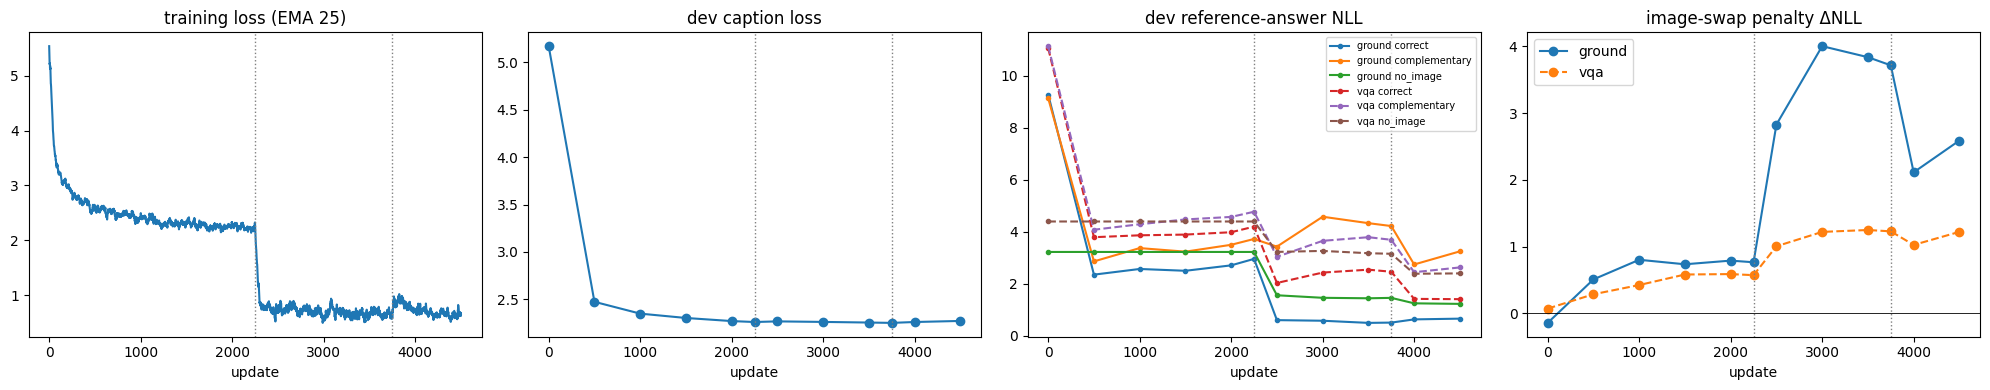

{
 "g": 4500,
 "train_time_s": {
  "stage1_caption": 2752.4368312358856,
  "stage2_instruct": 2078.9534633159637,
  "stage3_vqa": 1028.2636110782623
 },
 "peak_mem_GB": 2.1606602668762207,
 "skipped": [
  1,
  2,
  3,
  4,
  7
 ],
 "trainable_by_stage": {
  "stage1_caption": 1837056,
  "stage2_instruct": 6424576,
  "stage3_vqa": 6424576
 },
 "sessions": 1,
 "feature_caching": {
  "download_s": 118.46788430213928,
  "encode_s": 220.25972056388855,
  "peak_gpu_mem_GB": 1.762681007385254,
  "n_images": 9279,
  "feature_dtype": "float16",
  "shape": [
   196,
   768
  ]
 },
 "gpu": "Tesla T4"
}


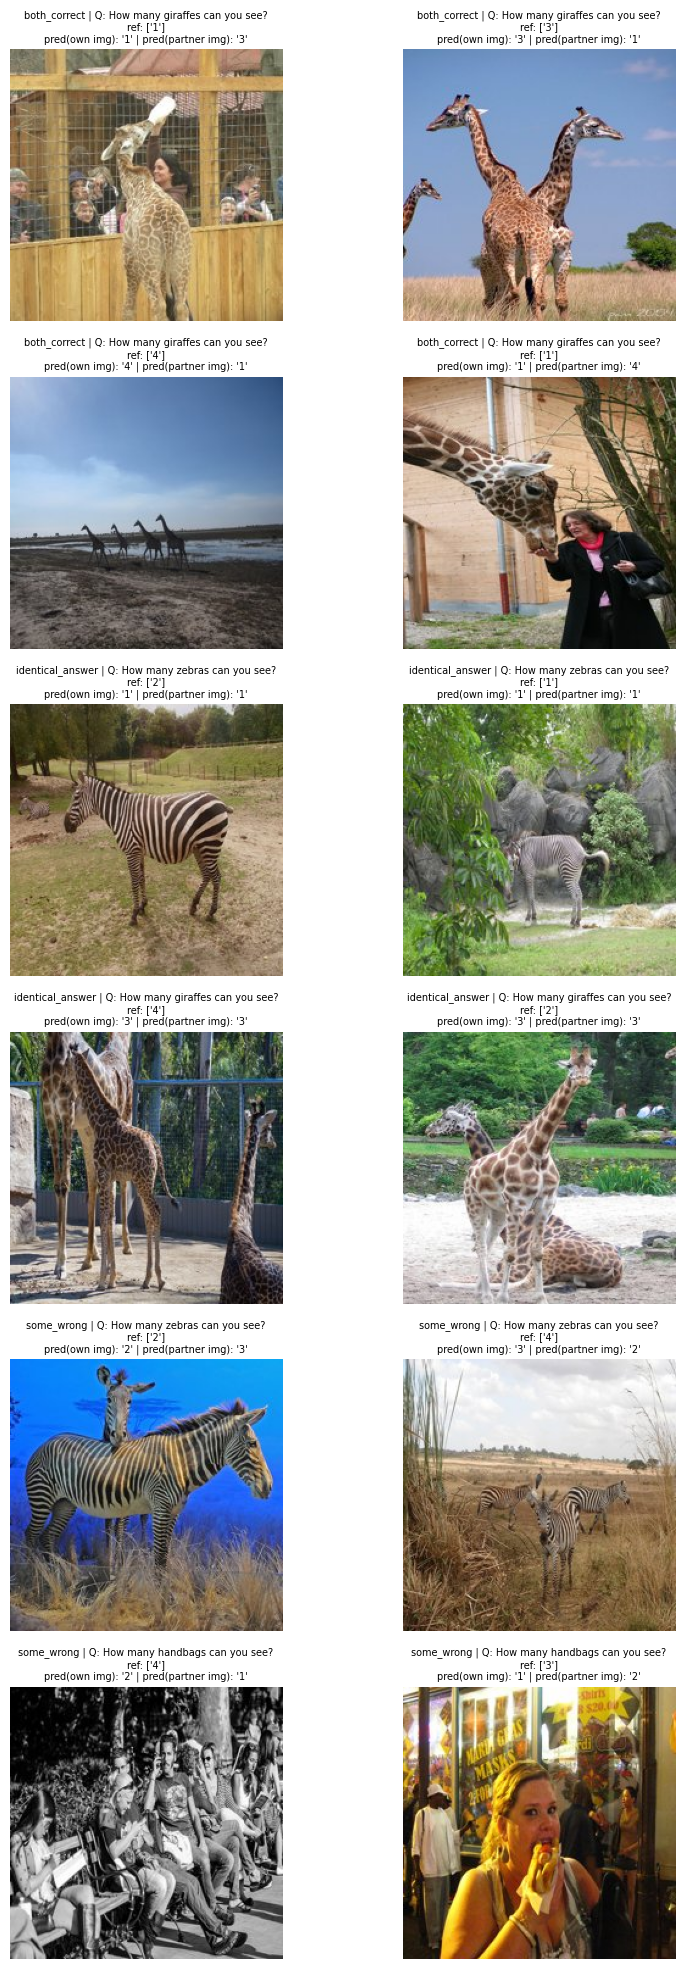

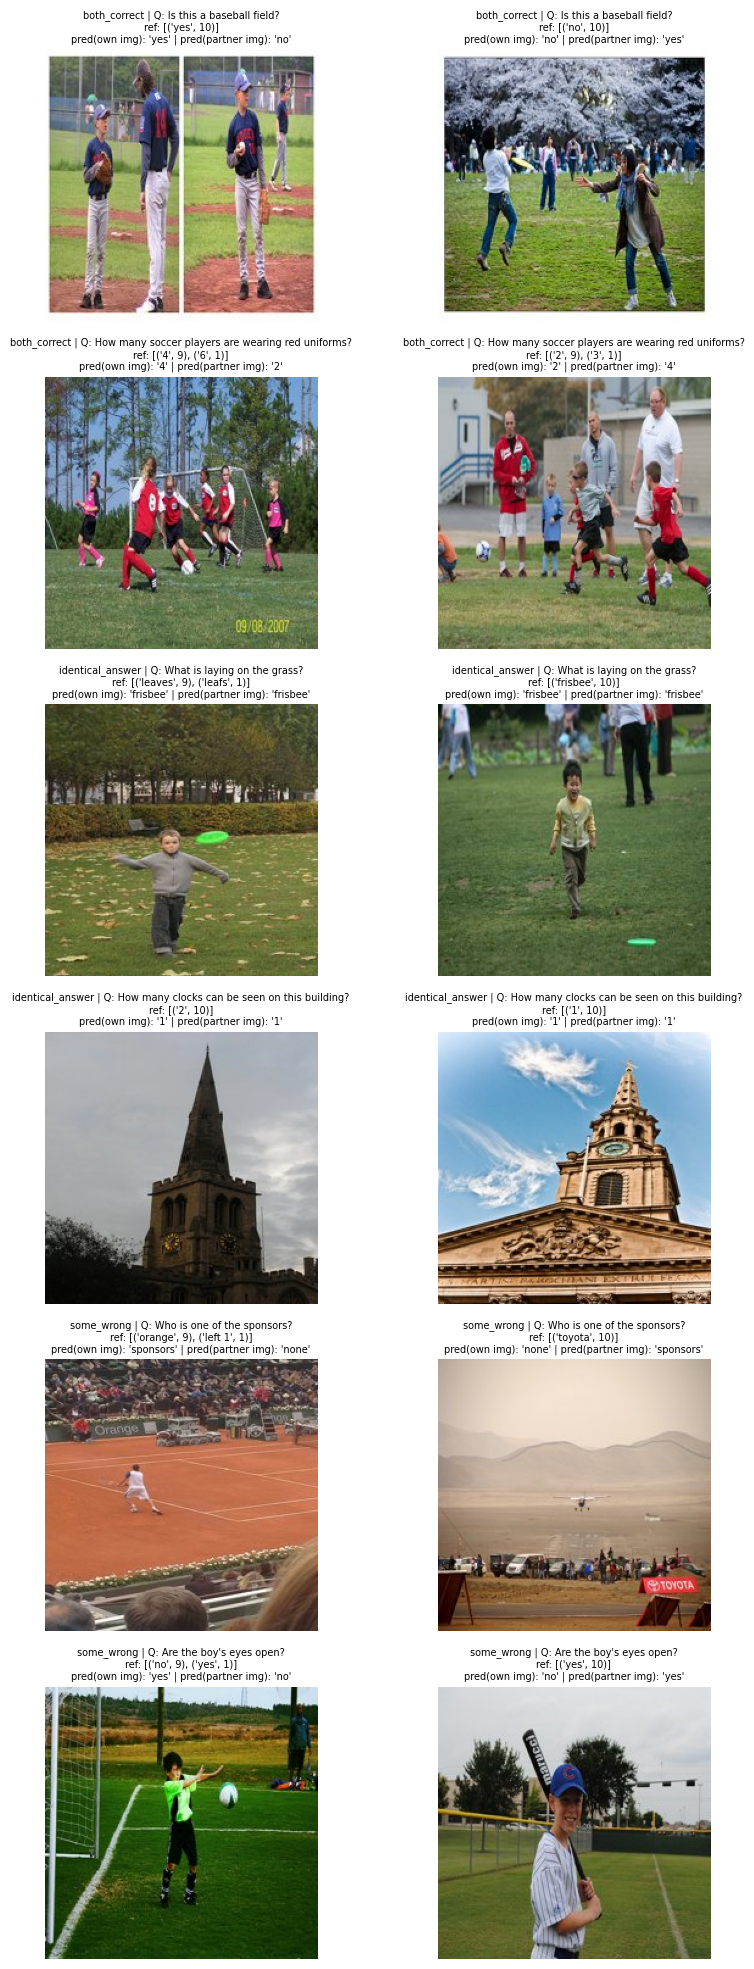

All Task 2 outputs are in /content/drive/MyDrive/ATML_PA3/task2/runs/tok196


In [12]:
# Step 6 — learning curves, resources and aligned qualitative examples
import matplotlib.pyplot as plt
tl = pd.read_json(RUN / "train_log.jsonl", lines=True); dv = pd.read_json(RUN / "dev_log.jsonl", lines=True).sort_values("update")
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].plot(tl["update"], tl["loss"].ewm(span=25).mean()); ax[0].set(title="training loss (EMA 25)", xlabel="update")
ax[1].plot(dv["update"], dv["caption_dev_loss"], "o-"); ax[1].set(title="dev caption loss", xlabel="update")
for nm, ls in [("ground", "-"), ("vqa", "--")]:
    for c in ["correct", "complementary", "no_image"]:
        ax[2].plot(dv["update"], dv[f"{nm}_nll_{c}"], ls, marker="o", ms=3, label=f"{nm} {c}")
    ax[3].plot(dv["update"], dv[f"{nm}_swap_penalty"], ls, marker="o", label=nm)
ax[2].set(title="dev reference-answer NLL", xlabel="update"); ax[2].legend(fontsize=7)
ax[3].axhline(0, c="k", lw=.6); ax[3].set(title="image-swap penalty ΔNLL", xlabel="update"); ax[3].legend()
for a in ax:
    for b in STAGE_END[:-1]: a.axvline(b, c="gray", ls=":", lw=1)
plt.tight_layout(); plt.savefig(RUN / "learning_curves.png", dpi=150); plt.show()
print(json.dumps(jload(RUN / "train_resources.json"), indent=1, default=str)[:2000])

# aligned complementary-pair examples. Selection rule (stated, deterministic): for each suite, the first two
# pairs in pair-ID order from each outcome group — (a) both correct with correct images, (b) identical answer
# for both images, (c) at least one wrong with the correct image.
def outcome(p_rows):
    a, b = p_rows
    if a["pred_norm"] == b["pred_norm"]: return "identical_answer"
    if a["exact"] and b["exact"]: return "both_correct"
    return "some_wrong"
for nm in SUITES:
    by = defaultdict(list)
    for r in R[(nm, "correct")]: by[r["pair_id"]].append(r)
    swap = {r["ex"]: r for r in R[(nm, "complementary")]}
    groups = defaultdict(list)
    for pid in sorted(by): groups[outcome(by[pid])].append(pid)
    chosen = [pid for gname in ["both_correct", "identical_answer", "some_wrong"] for pid in groups[gname][:2]]
    if not chosen: continue
    fig, axs = plt.subplots(len(chosen), 2, figsize=(9, 3.3 * len(chosen)))
    axs = np.atleast_2d(axs)
    for row_i, pid in enumerate(chosen):
        for col, r in enumerate(by[pid]):
            ax_ = axs[row_i, col]
            th = ROOT / "thumbs" / (r["img"].replace("/", "_") + ".jpg")
            if th.exists(): ax_.imshow(Image.open(th))
            ax_.axis("off")
            refs = r["refs"] if nm == "ground" else Counter(vqa_normalize(a) for a in r["refs"]).most_common(3)
            ax_.set_title(f"{outcome(by[pid])} | Q: {r['question'][:55]}\nref: {refs}\npred(own img): {r['pred']!r} | "
                          f"pred(partner img): {swap[r['ex']]['pred']!r}", fontsize=7)
    plt.tight_layout(); plt.savefig(RUN / f"qualitative_{nm}.png", dpi=130); plt.show()
print("All Task 2 outputs are in", RUN)

In [13]:
# Optional — compare the 196-token and 49-token runs (run this after both runs finished)
both = [ROOT / "runs" / t for t in ["tok196", "tok49"]]
if all((r / "final_summary.csv").exists() for r in both):
    cmp = pd.concat([pd.read_csv(r / "final_summary.csv").assign(run=r.name) for r in both])
    print(cmp.pivot_table(index=["suite", "condition"], columns="run", values=["accuracy", "pair_accuracy", "mean_ref_nll"]).round(3))
    for r in both:
        res = jload(r / "train_resources.json")
        print(r.name, "train time (h):", round(sum(res["train_time_s"].values()) / 3600, 2), "| peak mem GB:",
              round(res["peak_mem_GB"], 2), "| gen ms/answer:",
              pd.read_csv(r / "final_summary.csv")["gen_time_ms_per_answer"].mean().round(2))
else:
    print("comparison needs both runs (set N_VIS = 49 at the top and run the notebook again)")

comparison needs both runs (set N_VIS = 49 at the top and run the notebook again)
